# TGLF surrogate: evaluation

This notebook completes assignment **Steps 4–5**: held-out test accuracy, training
and prediction speed, learning curves, and the 43 original SAT3 cases. It uses
the selected GELU/ReLU five-network ensemble and the required mean and linear baselines.
The activation ranking used validation error. This test set was already inspected
in earlier work, so these refreshed test results are exploratory rather than a
new untouched assessment. The SAT3 cases did not select the model.

The cells reproduce the report from saved DSMLP results and check the selected
model's predictions. They do not retrain or tune a model.
[1. Prepare data](01_prepare_data.ipynb) · [2. NN ensemble](02_nn_ensemble.ipynb) · [3. Evaluation](03_evaluation.ipynb)

In [1]:
from pathlib import Path
import json
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

candidates = [q for p in (Path.cwd(), *Path.cwd().parents) for q in (p, p / "assignments/A2")]
A2_DIR = next(p for p in candidates if (p / "nn_ensemble.py").is_file() and (p / "models").is_dir())
sys.path.insert(0, str(A2_DIR))
import torch
from nn_ensemble import TARGETS, digest, load_ensemble
from evaluate_surrogate import nn_raw_prediction, baseline_prediction, metrics
from evaluate_sat3 import engineer_features, trend_rows, GRADIENT_LETTERS, ISOTOPES

torch.set_num_threads(2)
RESULTS, FIGURES = A2_DIR / "results", A2_DIR / "figures"
SAT3 = RESULTS / "sat3"
INPUTS = A2_DIR / "prepared/sat3"
MODEL_NAMES = ["mean", "linear", "nn_ensemble_equal5"]
LABELS = {"mean": "Mean baseline", "linear": "Linear regression", "nn_ensemble_equal5": "Five-NN ensemble"}
COLORS = {"mean": "#888888", "linear": "#ce8a32", "nn_ensemble_equal5": "#245c82"}
TITLES = {"Q_i": "Ion heat flux", "Q_e": "Electron heat flux", "Gamma_e": "Electron particle flux"}
COLOR = COLORS["nn_ensemble_equal5"]
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
metadata = json.loads((RESULTS / "metadata.json").read_text())
for name, checksum in metadata["artifact_sha256"].items():
    assert digest(A2_DIR / name) == checksum, name
scores = pd.read_csv(RESULTS / "test_metrics.csv")
predictions = pd.read_csv(RESULTS / "test_predictions.csv", float_precision="round_trip")
curve = pd.read_csv(RESULTS / "learning_curve_metrics.csv")
curve_predictions = pd.read_csv(RESULTS / "learning_curve_predictions.csv", float_precision="round_trip")
timing = pd.read_csv(RESULTS / "inference_timing.csv")
training = pd.read_csv(RESULTS / "training_timing.csv")
members = load_ensemble(A2_DIR / "models")
baselines = joblib.load(A2_DIR / "models/baseline_models.joblib")
print("Verified saved model and result files. Training / validation / test: 3,496 / 750 / 750.")

Verified saved model and result files. Training / validation / test: 3,496 / 750 / 750.


## 1. Accuracy on the 750-case test set

RMSE is in original gyro-Bohm units; lower is better. R² is dimensionless;
higher is better. The mean baseline uses training means, so its test R² can be
slightly negative. The parity plots include every test case and use matching
axis limits across models within each output.

In [2]:
assert set(scores.model) == set(MODEL_NAMES) and len(scores) == 9
assert scores.n_cases.eq(750).all() and scores.split.eq("test").all()
report = scores.assign(model=scores.model.map(LABELS)).pivot(index="model", columns="target", values=["rmse_gb", "r2"])
report = report.reindex([LABELS[m] for m in MODEL_NAMES])
report = report.reindex(columns=pd.MultiIndex.from_product([["rmse_gb", "r2"], TARGETS]))
report.columns = pd.MultiIndex.from_tuples([("RMSE (gyro-Bohm)" if metric == "rmse_gb" else "R²", t) for metric, t in report.columns])
display(report.round(4))

by_model = scores.set_index(["model", "target"])
reductions = pd.Series({t: 100 * (1 - by_model.loc[("nn_ensemble_equal5", t), "rmse_gb"] / by_model.loc[("linear", t), "rmse_gb"]) for t in TARGETS})
display(Markdown("Relative to linear regression, the ensemble reduces test RMSE by " +
                 ", ".join(f"**{reductions[t]:.1f}% for {t}**" for t in TARGETS) + "."))

RMSE (gyro-Bohm)                        R²                
                               Q_i      Q_e  Gamma_e     Q_i     Q_e Gamma_e
model                                                                       
Mean baseline              76.5301  60.2047  20.9255 -0.0089 -0.0095 -0.0109
Linear regression          38.4287  29.4790  14.4287  0.7456  0.7580  0.5194
Five-NN ensemble           15.5294  11.2706   3.2885  0.9585  0.9646  0.9750

Relative to linear regression, the ensemble reduces test RMSE by **59.6% for Q_i**, **61.8% for Q_e**, **77.2% for Gamma_e**.

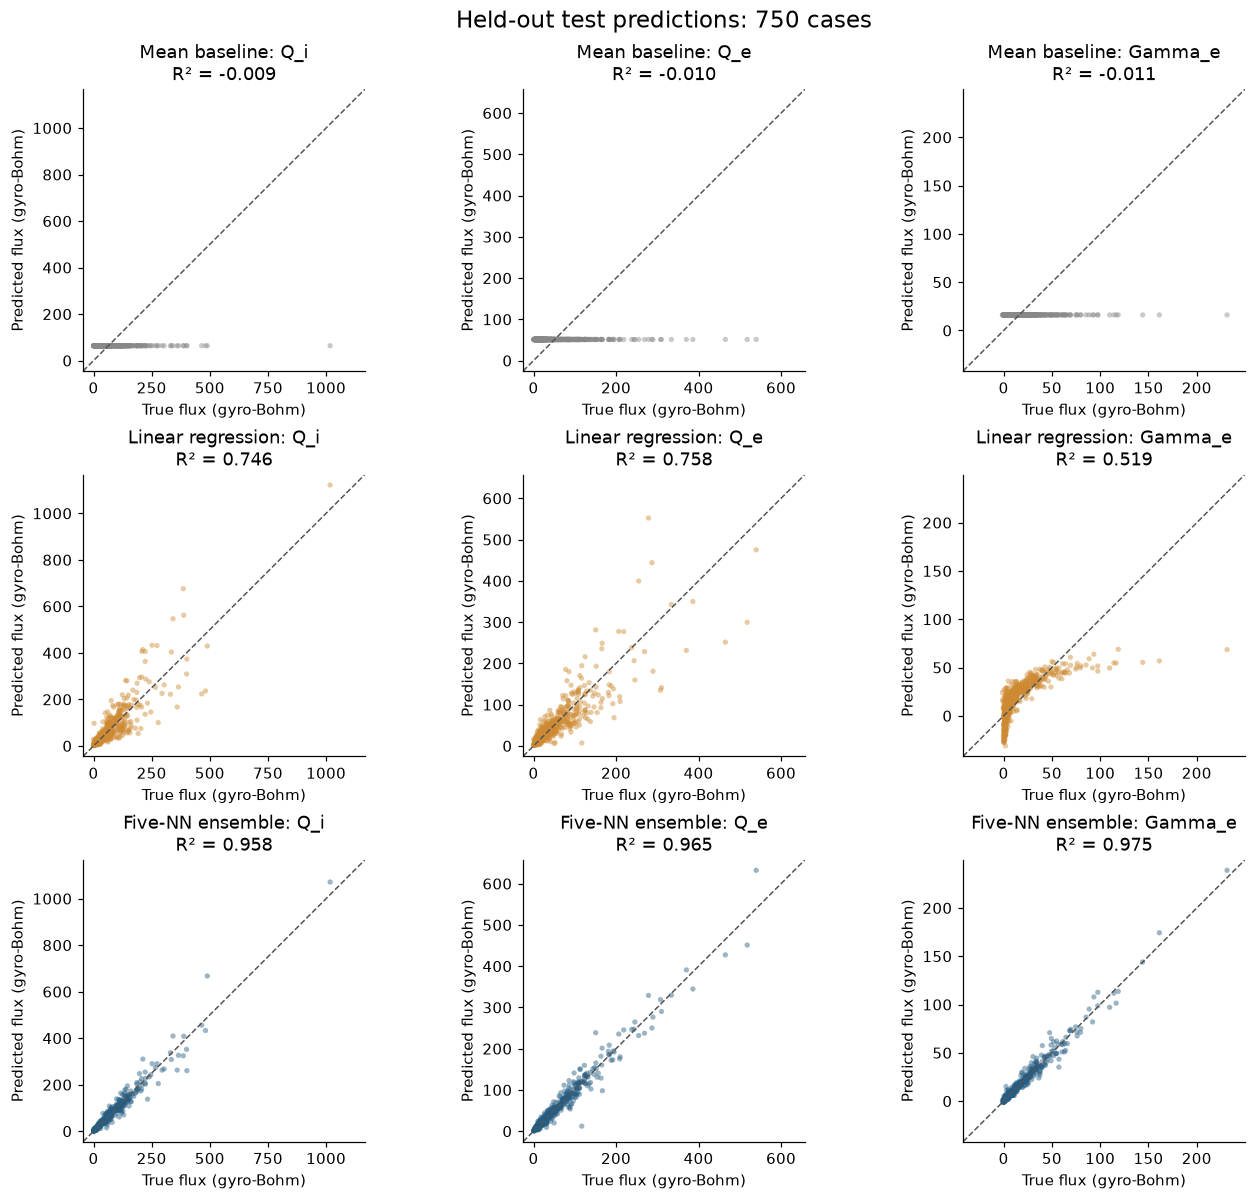

In [3]:
fig, axes = plt.subplots(3, 3, figsize=(12, 10.8), constrained_layout=True)
for j, target in enumerate(TARGETS):
    values = predictions[[f"{target}_true", f"{target}_prediction"]].to_numpy().ravel()
    lo, hi = min(0.0, values.min()), values.max()
    pad = 0.04 * (hi - lo)
    limits = (lo - pad, hi + pad)
    for i, model in enumerate(MODEL_NAMES):
        part = predictions.loc[predictions.model.eq(model)]
        ax = axes[i, j]
        ax.scatter(part[f"{target}_true"], part[f"{target}_prediction"], s=12, alpha=0.45, edgecolors="none", color=COLORS[model])
        ax.plot(limits, limits, "--", color="#555555", linewidth=1)
        r2 = by_model.loc[(model, target), "r2"]
        ax.set(xlim=limits, ylim=limits, xlabel="True flux (gyro-Bohm)", ylabel="Predicted flux (gyro-Bohm)",
               title=f"{LABELS[model]}: {target}\nR² = {r2:.3f}")
        ax.set_aspect("equal", adjustable="box")
fig.suptitle("Held-out test predictions: 750 cases", fontsize=15)
fig.savefig(FIGURES / "10_test_parity.png", bbox_inches="tight")
plt.show()

## 2. Training and prediction speed

These are measurements from the completed DSMLP CPU run. Training used four
threads and trained the five members sequentially; prediction used one thread.
NN training time includes scaling, warmup, validation, and checkpoint work.
Baseline times include scaling and fitting.

Prediction includes input scaling, inverse target transformations, and averaging.
It excludes model loading, file access, and construction of the 11 physical
features. Reported medians use seven repetitions after warmup. Single-case
latency measures one request; batch time per case measures throughput across
750 cases. These are different quantities.

mode,Training time (s),Batch time per case (µs),Single-case latency (µs)
model,,,
Mean baseline,0.0014,0.0162,7.1136
Linear regression,0.0045,0.3994,226.9196
Five-NN ensemble,24.0119,4.5100,814.3493


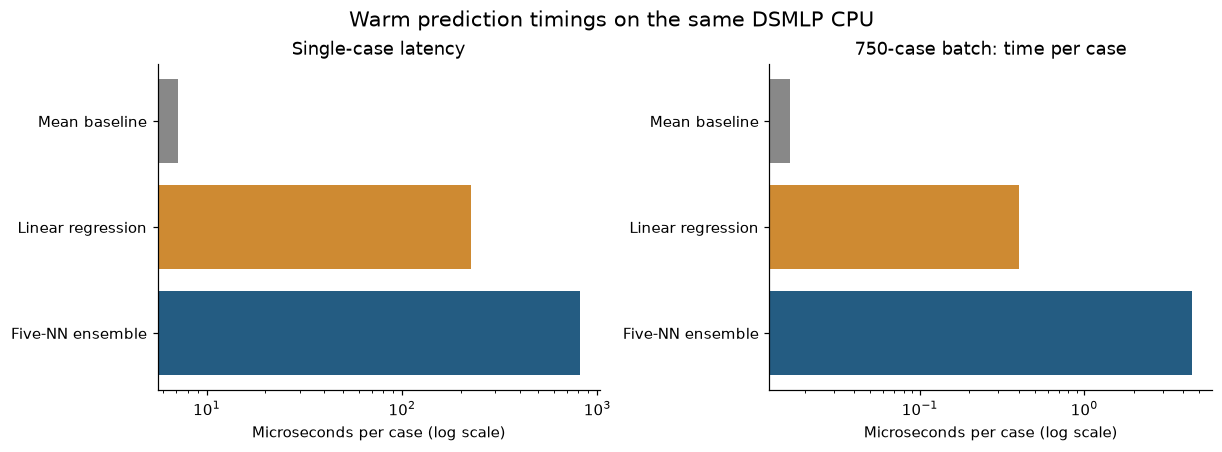

The ensemble took **24.01 s** to retrain all five networks on 3,496 cases. Its median single-case latency was **0.814 ms**; a 750-case batch averaged **4.51 µs per case**. The assignment describes TGLF runs as taking seconds per case. These measured surrogate times are much shorter, but the supplied TGLF run logs contain no elapsed runtimes, so we cannot report a measured TGLF-to-surrogate speedup ratio.

In [4]:
speed_table = timing.assign(model=timing.model.map(LABELS)).pivot(index="model", columns="mode", values="median_us")
speed_table = speed_table.reindex([LABELS[m] for m in MODEL_NAMES])
speed_table = speed_table.rename(columns={"single_case": "Single-case latency (µs)", "batch": "Batch time per case (µs)"})
fit_seconds = timing.groupby("model").training_seconds.first().rename(index=LABELS)
speed_table.insert(0, "Training time (s)", fit_seconds)
display(speed_table.round(4))


fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
order = MODEL_NAMES
for ax, mode, title in zip(axes, ["single_case", "batch"], ["Single-case latency", "750-case batch: time per case"]):
    part = timing.loc[timing["mode"].eq(mode)].set_index("model").loc[order]
    ax.barh([LABELS[m] for m in order], part.median_us, color=[COLORS[m] for m in order])
    ax.set_xscale("log")
    ax.set(title=title, xlabel="Microseconds per case (log scale)")
    ax.invert_yaxis()
fig.suptitle("Warm prediction timings on the same DSMLP CPU", fontsize=14)
fig.savefig(FIGURES / "11_prediction_speed.png", bbox_inches="tight")
plt.show()

ensemble_timing = timing.loc[timing.model.eq("nn_ensemble_equal5")].set_index("mode")
single_us = ensemble_timing.loc["single_case", "median_us"]
batch_us = ensemble_timing.loc["batch", "median_us"]
ensemble_fit = fit_seconds[LABELS["nn_ensemble_equal5"]]
display(Markdown(
    f"The ensemble took **{ensemble_fit:.2f} s** to retrain all five networks on 3,496 cases. "
    f"Its median single-case latency was **{single_us / 1000:.3f} ms**; "
    f"a 750-case batch averaged **{batch_us:.2f} µs per case**. "
    "The assignment describes TGLF runs as taking seconds per case. These measured "
    "surrogate times are much shorter, but the supplied TGLF run logs contain no "
    "elapsed runtimes, so we cannot report a measured TGLF-to-surrogate speedup ratio."
))

## 3. Learning curves

Both baselines and all five NN members were retrained on nested subsets of
**250, 500, 1,000, 2,000, and 3,496 training cases**. A fixed permutation with
seed 2026 defines the subsets. Scalers are refitted on each subset, and the same
separate 750 validation cases select checkpoints. All settings stay fixed;
all fits finished before test evaluation.

This is one nested sample sequence, so the curves have no resampling uncertainty
bands. With a fixed epoch budget, larger datasets also receive more minibatch
updates per epoch. The epoch budget can also limit
optimization on smaller subsets.

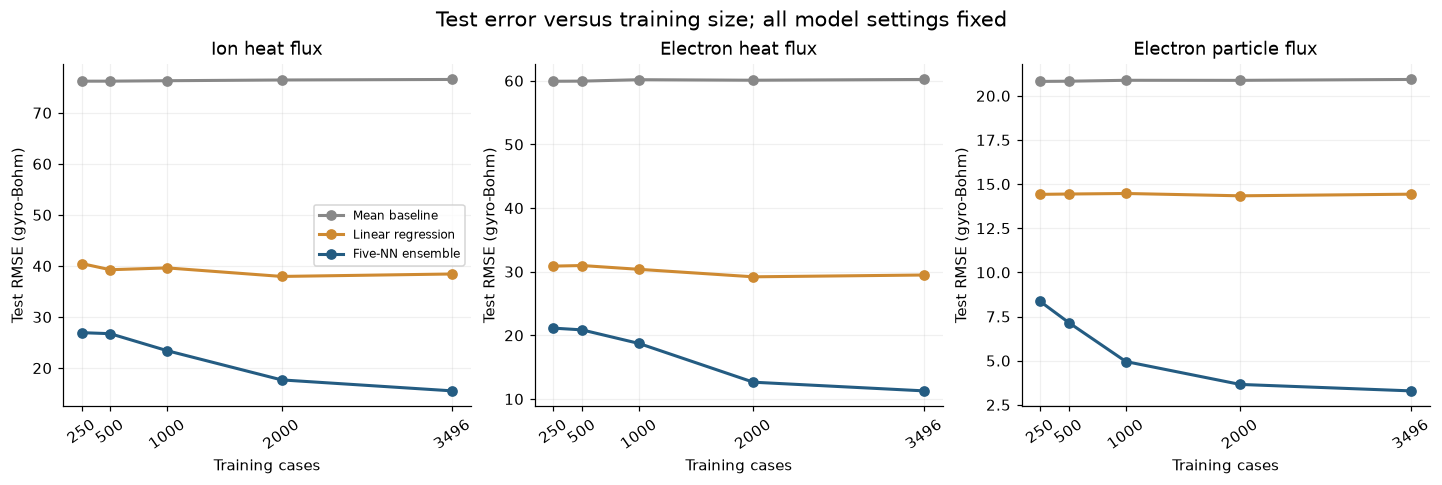

target                         Q_i      Q_e  Gamma_e
model             n_train                           
Five-NN ensemble  250      26.9352  21.1309   8.3544
                  500      26.7358  20.8584   7.1557
                  1000     23.3949  18.7183   4.9493
                  2000     17.6823  12.6364   3.6547
                  3496     15.5294  11.2706   3.2885
Linear regression 250      40.4715  30.8751  14.4188
                  500      39.2628  30.9686  14.4377
                  1000     39.6171  30.3702  14.4680
                  2000     37.9482  29.1947  14.3368
                  3496     38.4287  29.4790  14.4287
Mean baseline     250      76.1934  59.9225  20.8147
                  500      76.1985  59.9434  20.8268
                  1000     76.2845  60.1664  20.8782
                  2000     76.4257  60.0848  20.8752
                  3496     76.5301  60.2047  20.9255

From 250 to 3,496 training cases, the ensemble's mean normalized test RMSE changed by **-50.2%**, versus **-2.9%** for linear regression. The ensemble's change from 2,000 to 3,496 cases was **-11.1%**. Normalization uses each target's standard deviation in the full training set for every curve point, so changing subset scales do not drive this comparison.

Mean normalized test error falls at every larger training size in this run.

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.3), constrained_layout=True)
for ax, target in zip(axes, TARGETS):
    for model in MODEL_NAMES:
        part = curve.loc[curve.model.eq(model) & curve.target.eq(target)].sort_values("n_train")
        ax.plot(part.n_train, part.rmse_gb, "o-", color=COLORS[model], label=LABELS[model], linewidth=2)
    ax.set(title=TITLES[target], xlabel="Training cases", ylabel="Test RMSE (gyro-Bohm)", xticks=metadata["training_sizes"])
    ax.tick_params(axis="x", labelrotation=35)
    ax.grid(alpha=0.18)
axes[0].legend(fontsize=8)
fig.suptitle("Test error versus training size; all model settings fixed", fontsize=14)
fig.savefig(FIGURES / "12_learning_curves.png", bbox_inches="tight")
plt.show()

learning_table = curve.assign(model=curve.model.map(LABELS)).pivot(index=["model", "n_train"], columns="target", values="rmse_gb")
display(learning_table.reindex(columns=TARGETS).round(4))


# Use one fixed normalization for comparisons across training sizes.
train_std = pd.read_csv(A2_DIR / "prepared/targets_raw.csv", index_col="case").loc[
    pd.read_csv(RESULTS / "subset_order.csv").case
].std(ddof=0)
aggregate = curve.assign(normalized_rmse=curve.rmse_gb / curve.target.map(train_std)).groupby(["model", "n_train"]).normalized_rmse.mean().unstack("model")

first, middle, last = aggregate.loc[250], aggregate.loc[2000], aggregate.loc[3496]
ensemble_drop = 100 * (1 - last.nn_ensemble_equal5 / first.nn_ensemble_equal5)
last_drop = 100 * (1 - last.nn_ensemble_equal5 / middle.nn_ensemble_equal5)
linear_drop = 100 * (1 - last.linear / first.linear)
display(Markdown(
    f"From 250 to 3,496 training cases, the ensemble's mean normalized test RMSE "
    f"changed by **{-ensemble_drop:+.1f}%**, versus **{-linear_drop:+.1f}%** for linear regression. "
    f"The ensemble's change from 2,000 to 3,496 cases was **{-last_drop:+.1f}%**. "
    "Normalization uses each target's standard deviation in the full training set "
    "for every curve point, so changing subset scales do not drive this comparison."
))

by_size = aggregate['nn_ensemble_equal5'].sort_index()
if (by_size.diff().dropna() < 0).all():
    display(Markdown("Mean normalized test error falls at every larger training size in this run."))
else:
    display(Markdown("Mean normalized test error does not fall at every larger size in this run."))


More training cases can be evaluated against the remaining error, the required
accuracy, and the actual cost of generating TGLF simulations. One nested sample
sequence does not establish an uncertainty interval or guarantee future gains.

## 4. Outside evaluation: all 43 SAT3 cases

SAT3 contains controlled scans around a reference case. We use its supplied
`tglf_sat2` outputs, as in Task 1, rather than nonlinear CGYRO fluxes. The same
11 feature definitions and trained scalers are applied to all 43 cases. None
are excluded, including negative particle flux.

Many scan values sit on the boundaries of the training design. The flux ranges
are narrower than in the random test set: maximum ion heat is 122.78 versus
1,017.30. Therefore, compare R² as well as absolute RMSE. These related scan
cases do not cover every combination of the inputs.

In [6]:
input_meta = json.loads((INPUTS / "input_metadata.json").read_text())
table = pd.read_csv(INPUTS / "sat3_table.csv", index_col="case", float_precision="round_trip")
sat_features = pd.read_csv(INPUTS / "features.csv", index_col="case", float_precision="round_trip")
sat_targets = pd.read_csv(INPUTS / "targets_raw.csv", index_col="case", float_precision="round_trip")
sat_predictions = pd.read_csv(SAT3 / "predictions.csv", float_precision="round_trip")
ensemble = sat_predictions.loc[sat_predictions.model.eq("nn_ensemble_equal5")].set_index("case")
sat_scores = pd.read_csv(SAT3 / "metrics.csv")
comparison = pd.concat([scores, sat_scores], ignore_index=True)
selected_scores = comparison.loc[comparison.model.eq("nn_ensemble_equal5")]
report = selected_scores.pivot(index="target", columns="split", values=["rmse_gb", "r2"])
report = report.reindex(index=TARGETS, columns=pd.MultiIndex.from_product([["rmse_gb", "r2"], ["test", "sat3"]]))
report.columns = pd.MultiIndex.from_tuples([("RMSE (gyro-Bohm)" if metric == "rmse_gb" else "R²", "750 random test" if split == "test" else "43 SAT3") for metric, split in report.columns])
display(report.round(4))
errors = pd.read_csv(SAT3 / "case_errors.csv")
trends = pd.read_csv(SAT3 / "trend_checks.csv")
trend_summary = pd.read_csv(SAT3 / "trend_summary.csv")

previous = pd.read_csv(A2_DIR / "experiments/activation_reference/sat3_metrics.csv")
previous = previous.loc[previous.model.eq("nn_ensemble_equal5")].set_index("target")
current = sat_scores.loc[sat_scores.model.eq("nn_ensemble_equal5")].set_index("target")
display(Markdown("Compared with the previous GELU/tanh ensemble, SAT3 R² changes from " +
                 "; ".join(f"**{previous.loc[t, 'r2']:.4f} to {current.loc[t, 'r2']:.4f} for {t}**" for t in TARGETS) +
                 ". The validation winner does not improve every output on this external set."))


RMSE (gyro-Bohm)                      R²        
         750 random test 43 SAT3 750 random test 43 SAT3
target                                                  
Q_i              15.5294  4.2220          0.9585  0.9702
Q_e              11.2706  1.3345          0.9646  0.9973
Gamma_e           3.2885  1.1204          0.9750  0.9876

Compared with the previous GELU/tanh ensemble, SAT3 R² changes from **0.9867 to 0.9702 for Q_i**; **0.9890 to 0.9973 for Q_e**; **0.9910 to 0.9876 for Gamma_e**. The validation winner does not improve every output on this external set.

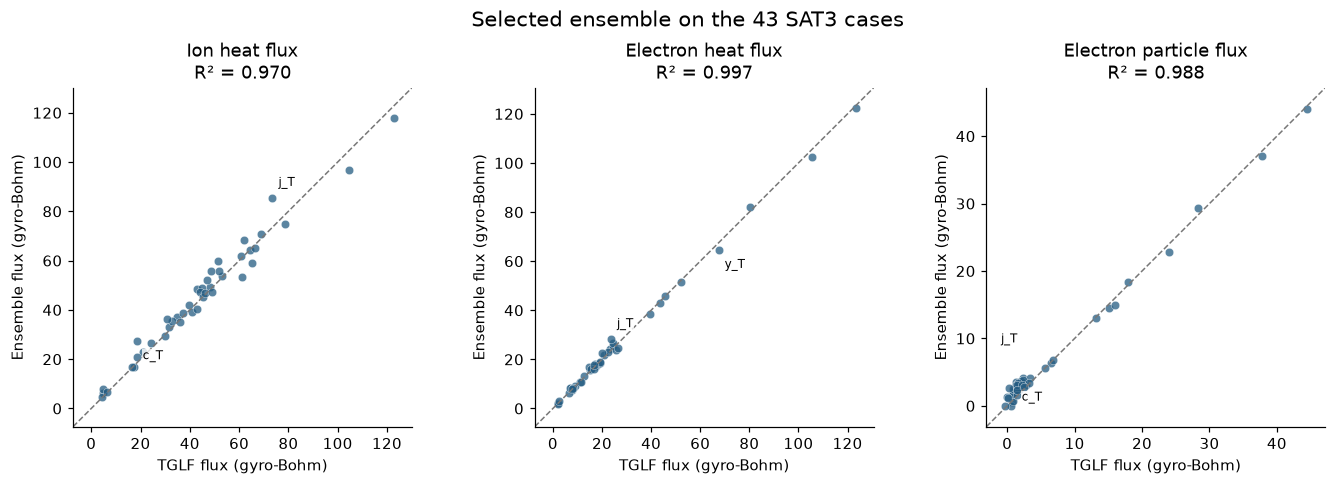

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.3), constrained_layout=True)
for ax, target in zip(axes, TARGETS):
    true, pred = ensemble[f"{target}_true"], ensemble[f"{target}_prediction"]
    values = np.concatenate([true, pred])
    lo, hi = min(0, values.min()), values.max()
    padding = 0.06 * (hi - lo)
    limits = (lo - padding, hi + padding)
    ax.scatter(true, pred, s=30, alpha=0.75, color=COLOR, edgecolors="white", linewidth=0.3)
    ax.plot(limits, limits, "--", color="#777777", linewidth=1)
    r2 = sat_scores.loc[sat_scores.model.eq("nn_ensemble_equal5") & sat_scores.target.eq(target), "r2"].iloc[0]
    ax.set(xlim=limits, ylim=limits, xlabel="TGLF flux (gyro-Bohm)", ylabel="Ensemble flux (gyro-Bohm)", title=f"{TITLES[target]}\nR² = {r2:.3f}")
    ax.set_aspect("equal", adjustable="box")
    worst = errors.loc[errors.target.eq(target)].nlargest(2, "absolute_error")
    for i, row in enumerate(worst.itertuples()):
        ax.annotate(row.case, (row.true, row.prediction), xytext=(-5, 30) if target == "Gamma_e" and row.case == "j_T" else (4, 8 if i == 0 else -12), textcoords="offset points", fontsize=8, bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=0.5))
fig.suptitle("Selected ensemble on the 43 SAT3 cases", fontsize=14)
fig.savefig(FIGURES / "13_sat3_parity.png", bbox_inches="tight")
plt.show()

## 5. Temperature-gradient and isotope trends

For cases **b, c, a, d**, electron and ion temperature gradients increase together
from 1.5 to 2.25, 3.0, and 3.5. Other model inputs remain fixed within each
isotope. Solid lines show TGLF; dashed lines show the ensemble. Lines connect
only the evaluated points.

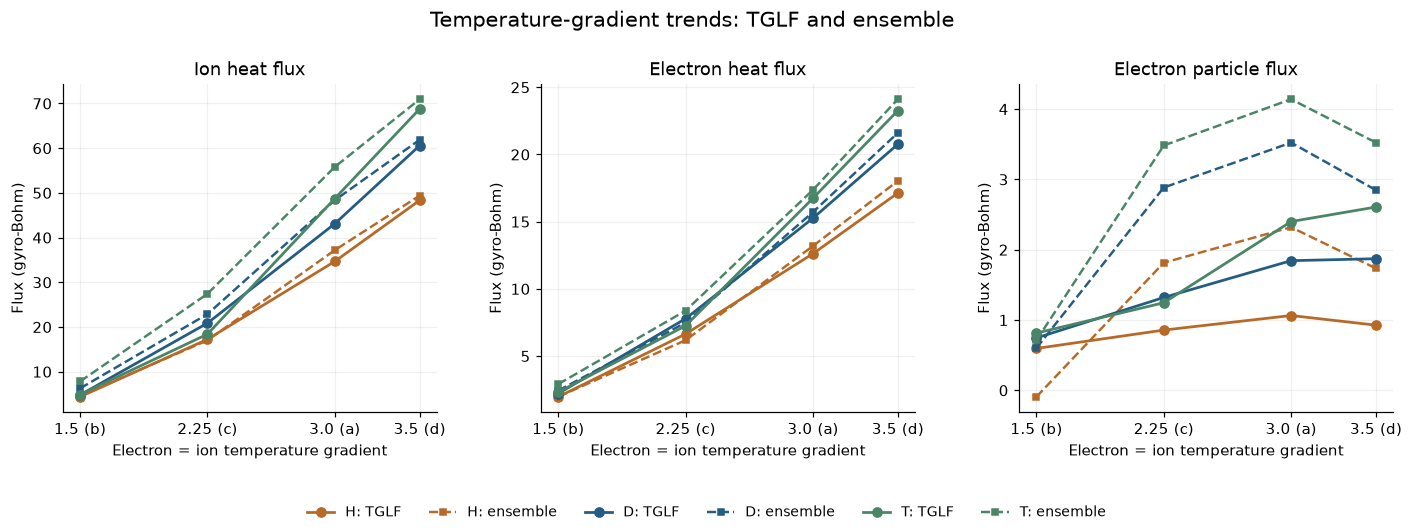

,matches,comparisons
target,,
Gamma_e,7,9
Q_e,9,9
Q_i,9,9


In [8]:
iso_colors = {"H": "#b76a28", "D": "#245c82", "T": "#498566"}
fig, axes = plt.subplots(1, 3, figsize=(13, 4.8))
for ax, target in zip(axes, TARGETS):
    for isotope in ISOTOPES:
        ids = [f"{letter}_{isotope}" for letter in GRADIENT_LETTERS]
        x = sat_features.loc[ids, "RLTS_1"].to_numpy()
        ax.plot(x, table.loc[ids, target], "o-", color=iso_colors[isotope], label=f"{isotope}: TGLF", linewidth=1.8)
        ax.plot(x, ensemble.loc[ids, f"{target}_prediction"], "s--", color=iso_colors[isotope], label=f"{isotope}: ensemble", linewidth=1.6, markersize=4)
    ax.set(title=TITLES[target], xlabel="Electron = ion temperature gradient", ylabel="Flux (gyro-Bohm)",
           xticks=[1.5, 2.25, 3.0, 3.5], xticklabels=["1.5 (b)", "2.25 (c)", "3.0 (a)", "3.5 (d)"])
    ax.grid(alpha=0.18)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=6, fontsize=9, frameon=False)
fig.suptitle("Temperature-gradient trends: TGLF and ensemble", fontsize=14)
fig.subplots_adjust(left=0.06, right=0.99, top=0.84, bottom=0.22, wspace=0.28)
fig.savefig(FIGURES / "14_sat3_temperature_scan.png", bbox_inches="tight")
plt.show()
display(trend_summary.loc[trend_summary.scan.eq("temperature_gradient")].set_index("target")[["matches", "comparisons"]])

The table above counts matched temperature-scan directions. The isotope panels
below show all eight complete H/D/T triplets. Their other 10 model features are
equal within each triplet. Each panel has its own vertical scale. The y group has
only H and T; both remain in the overall 43-case scores.

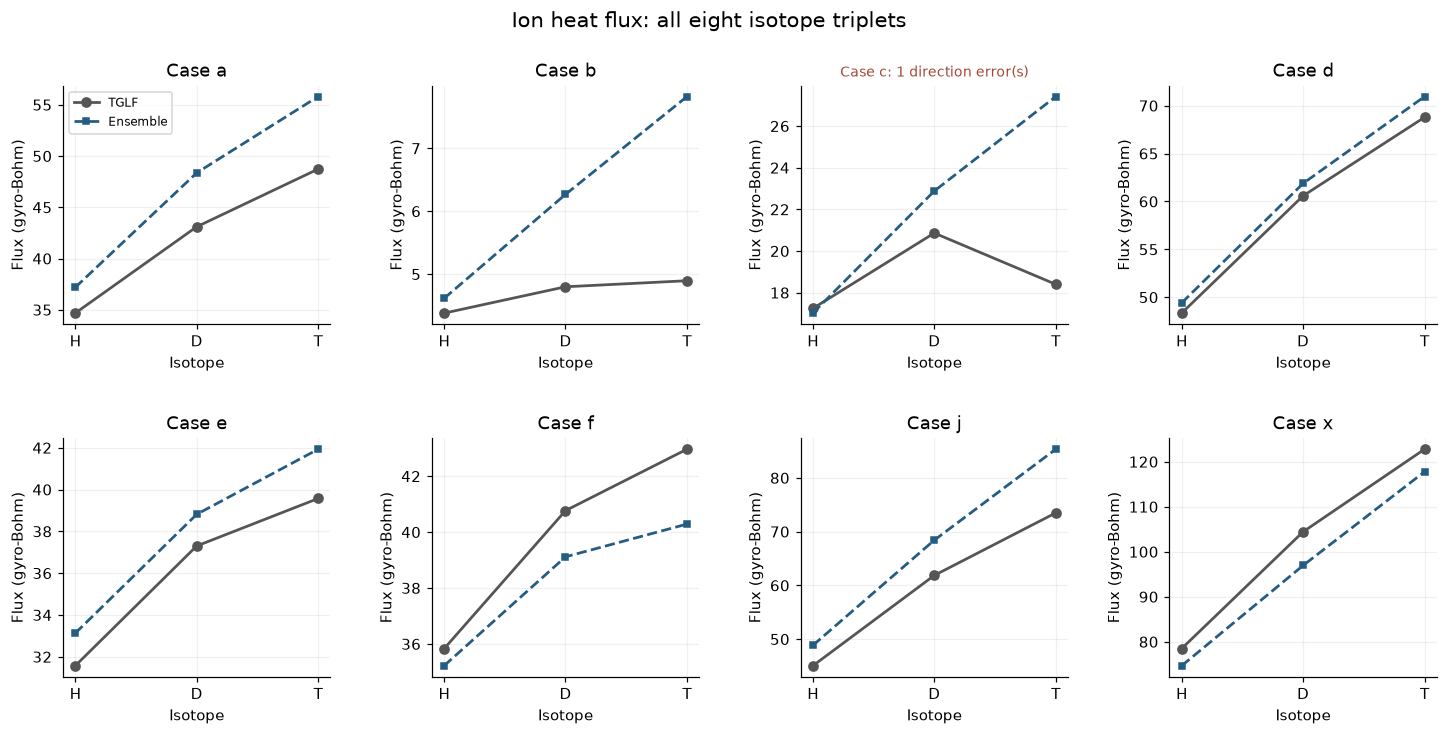

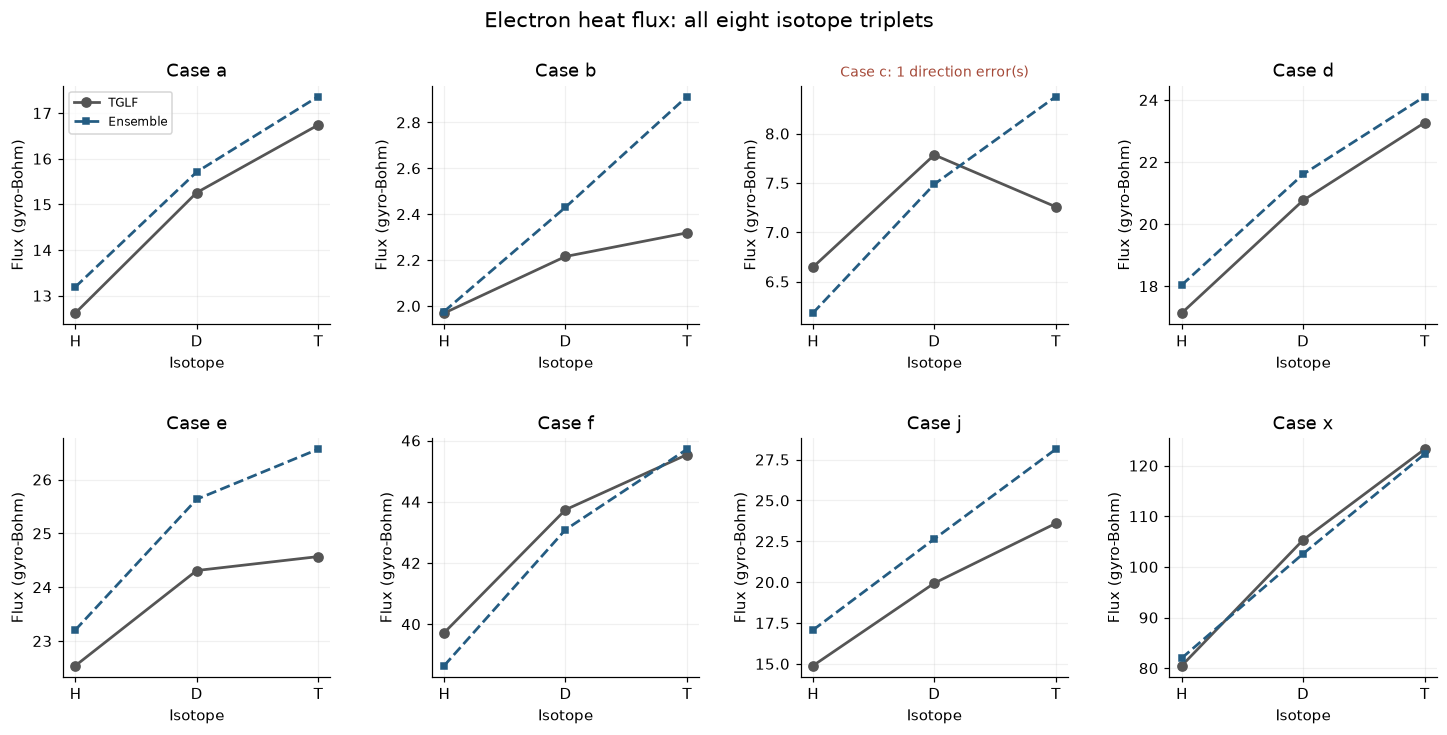

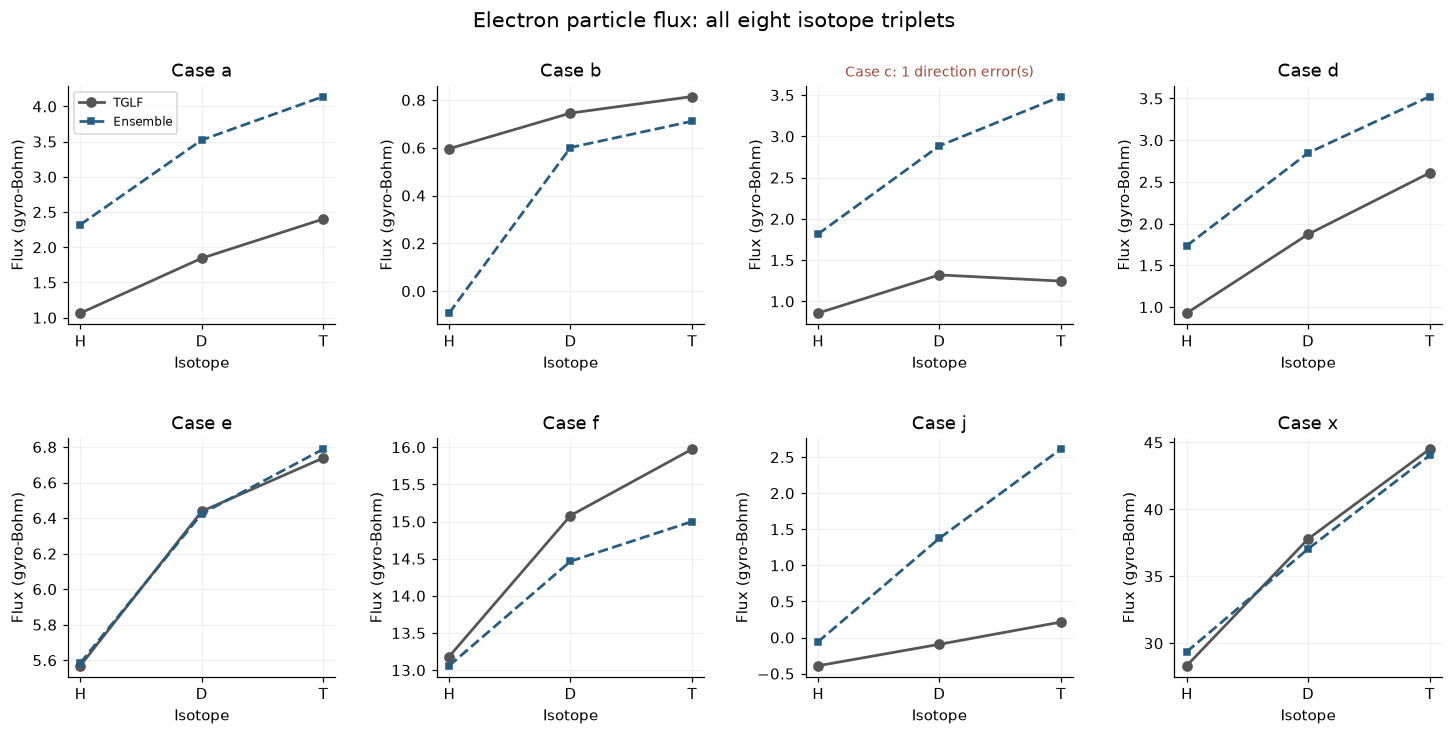

,matches,comparisons
target,,
Gamma_e,15,16
Q_e,15,16
Q_i,15,16


In [9]:
triplets = input_meta["complete_isotope_triplets"]
for number, target in enumerate(TARGETS, start=15):
    fig, axes = plt.subplots(2, 4, figsize=(13.5, 6.8))
    for ax, letter in zip(axes.flat, triplets):
        ids = [f"{letter}_{isotope}" for isotope in ISOTOPES]
        true = table.loc[ids, target].to_numpy()
        pred = ensemble.loc[ids, f"{target}_prediction"].to_numpy()
        ax.plot([0.5, 1.0, 1.5], true, "o-", color="#555555", label="TGLF", linewidth=1.8)
        ax.plot([0.5, 1.0, 1.5], pred, "s--", color=COLOR, label="Ensemble", linewidth=1.8, markersize=4)
        ax.set(title=f"Case {letter}", xticks=[0.5, 1.0, 1.5], xticklabels=["H", "D", "T"], xlabel="Isotope", ylabel="Flux (gyro-Bohm)")
        ax.grid(alpha=0.18)
        missed = trends.loc[trends.scan.eq("isotope") & trends.group.eq(letter) &
                            trends.target.eq(target) & ~trends.direction_matches]
        if len(missed):
            ax.set_title(f"Case {letter}: {len(missed)} direction error(s)", fontsize=9, color="#a44837")
    axes.flat[0].legend(fontsize=8)
    fig.suptitle(f"{TITLES[target]}: all eight isotope triplets", fontsize=14)
    fig.subplots_adjust(left=0.065, right=0.99, bottom=0.09, top=0.88, wspace=0.38, hspace=0.48)
    fig.savefig(FIGURES / f"{number:02d}_sat3_isotopes_{target}.png")
    plt.show()
display(trend_summary.loc[trend_summary.scan.eq("isotope")].set_index("target")[["matches", "comparisons"]])

The table below identifies direction and particle-flux sign errors for the
selected model. Overall R² does not guarantee every ordering or flux sign.

In [10]:
display(trends.loc[~trends.direction_matches, ["scan", "group", "target", "case_from", "case_to", "true_change", "predicted_change"]].round(5))
signs = ensemble[["Gamma_e_true", "Gamma_e_prediction"]].copy()
sign_errors = np.sign(signs.Gamma_e_true).ne(np.sign(signs.Gamma_e_prediction))
display(signs.loc[sign_errors].round(5))
for scan in ['temperature_gradient', 'isotope']:
    part = trends.loc[trends.scan.eq(scan)]
    display(Markdown(f"**{scan.replace('_', ' ').capitalize()}:** {part.direction_matches.sum()} of {len(part)} directions match."))
display(Markdown(f"**Particle-flux sign errors:** {int(sign_errors.sum())} of {len(sign_errors)} cases."))


,scan,group,target,case_from,case_to,true_change,predicted_change
17,temperature_gradient,D,Gamma_e,a_D,d_D,0.0279,-0.67560
26,temperature_gradient,T,Gamma_e,a_T,d_T,0.2069,-0.61721
40,isotope,c,Q_i,c_D,c_T,-2.4620,4.53688
42,isotope,c,Q_e,c_D,c_T,-0.5263,0.88887
44,isotope,c,Gamma_e,c_D,c_T,-0.0749,0.59784


,Gamma_e_true,Gamma_e_prediction
case,,
b_H,0.59587,-0.09229
j_D,-0.09342,1.37455


**Temperature gradient:** 25 of 27 directions match.

**Isotope:** 45 of 48 directions match.

**Particle-flux sign errors:** 2 of 43 cases.

## 6. Check the results

Recompute the metrics and scan comparisons, confirm the training subsets, and
reload the selected ensemble to reproduce both test sets. These checks keep
the report tied to the saved data and trained weights.

In [11]:
all_features = pd.read_csv(A2_DIR / "prepared/features.csv", index_col="case", float_precision="round_trip")
all_targets = pd.read_csv(A2_DIR / "prepared/targets_raw.csv", index_col="case", float_precision="round_trip")
split = pd.read_csv(A2_DIR / "prepared/split_assignments.csv", index_col="case")["split"]
train_ids = all_features.index[split.loc[all_features.index].eq("train")]
test_ids = all_features.index[split.loc[all_features.index].eq("test")]
order = pd.read_csv(RESULTS / "subset_order.csv").case
np.testing.assert_array_equal(order, np.random.default_rng(metadata["subset_seed"]).permutation(train_ids))
assert set(order).isdisjoint(test_ids) and len(order) == 3496
assert metadata["test_run"]["fit_completed_utc"] <= metadata["test_run"]["test_evaluation_started_utc"]
for frame, expected, ids, true, split_name in [
    (predictions, scores, test_ids, all_targets.loc[test_ids], "test"),
    (curve_predictions, curve, test_ids, all_targets.loc[test_ids], "test"),
    (sat_predictions, sat_scores, sat_features.index, sat_targets, "sat3"),
]:
    rows = []
    for (model, n), part in frame.groupby(["model", "n_train"], sort=False):
        assert part.case.tolist() == ids.tolist()
        np.testing.assert_allclose(part[[f"{t}_true" for t in TARGETS]], true, rtol=1e-12, atol=1e-12)
        rows.extend(metrics(true.to_numpy(), part[[f"{t}_prediction" for t in TARGETS]].to_numpy(), model, split_name, n))
    keys = ["model", "target", "n_train"]
    np.testing.assert_allclose(pd.DataFrame(rows).set_index(keys)[["rmse_gb", "r2"]].sort_index(), expected.set_index(keys)[["rmse_gb", "r2"]].sort_index(), rtol=1e-10, atol=1e-10)
for frame, x in [(predictions, all_features.loc[test_ids]), (sat_predictions, sat_features)]:
    for model, part in frame.groupby("model", sort=False):
        actual = nn_raw_prediction(members, x.to_numpy()) if model == "nn_ensemble_equal5" else baseline_prediction(baselines, model, x)
        np.testing.assert_allclose(actual, part[[f"{t}_prediction" for t in TARGETS]], rtol=5e-4, atol=5e-4)
np.testing.assert_array_equal(sat_features, engineer_features(table, sat_features.columns.tolist()))
pd.testing.assert_frame_equal(trend_rows(table, ensemble), trends, check_exact=False, rtol=1e-10, atol=1e-10)
assert len(trends) == 75 and len(sat_features) == 43 and len(test_ids) == 750
print("Verified predictions, metrics, fixed training subsets, and all 75 scan comparisons.")

Verified predictions, metrics, fixed training subsets, and all 75 scan comparisons.


## Reproduce the evaluation

Use the saved DSMLP Python environment and [requirements.txt](requirements.txt).
After syncing this A2 folder, run in a course compute container:

```sh
cd ~/private/assignments/DSC180A-A2-gelu-relu
OMP_NUM_THREADS=4 OPENBLAS_NUM_THREADS=4 ~/private/.venvs/tglf-a2-py312/bin/python evaluate_surrogate.py --threads 4 --output-dir evaluation_repeat
OMP_NUM_THREADS=2 OPENBLAS_NUM_THREADS=2 ~/private/.venvs/tglf-a2-py312/bin/python evaluate_sat3.py --output-dir sat3_evaluation_repeat
```

The first runner repeats the fixed learning-curve fits, test metrics, and timing.
The second evaluates the saved ensemble on the prepared SAT3 inputs without
fitting. Use fresh output directories to preserve the completed results.
The selected checkpoints come from the GELU/ReLU comparison. The previous
GELU/tanh model and report are preserved in `../A2_archive/`.